# Rudamentary Forecasting for Atlanta Home Prices using the Data Analysis and the Forecasting Guide

In [1]:
# Import all the usual packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import requests
from getpass import getpass
from scipy.optimize import curve_fit
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit
from IPython.display import display, HTML
from bs4 import BeautifulSoup
from pathlib import Path
from IPython.display import display, HTML, display, Image as IPythonImage
import io, base64

plt.rcParams.update({"figure.figsize": (8, 3), "font.size": 11})

In [2]:
# Take the data from the FRED and load it into a pandas dataframe
df = pd.read_csv(r"C:\Users\mbadi\Documents\ECON422_MatthewBadillo\ATL_House_Price_75_24.csv", index_col=0, parse_dates=True)

# Display the first few rows of the dataframe
display(df.head())

,ATNHPIUS12060Q
observation_date,
1975-10-01,41.18
1976-01-01,38.45
1976-04-01,40.78
1976-07-01,42.41
1976-10-01,41.21


In [3]:
# Replace the "observation_date" into "Date" and "ATNHPIUS12060Q" into ATL_Housing_Price_Index
df = df.rename(columns={"observation_date": "Date", "ATNHPIUS12060Q": "ATL_Housing_Price_Index"})

# Display the first few rows of the dataframe
display(df.head())

,ATL_Housing_Price_Index
observation_date,
1975-10-01,41.18
1976-01-01,38.45
1976-04-01,40.78
1976-07-01,42.41
1976-10-01,41.21


## This Portion will check for all the rudamentary things I checked for in my data analysis, just for ATL house prices:

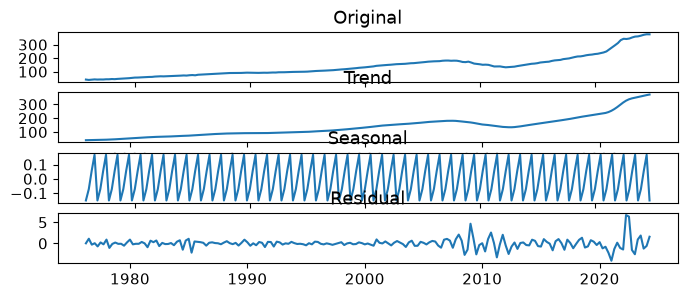

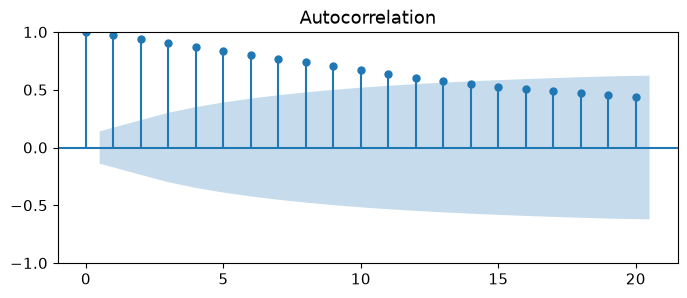

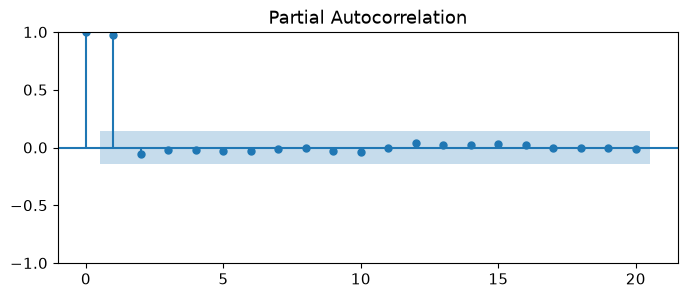

ADF Statistic: 1.0396762693423136
p-value: 0.9946674297481001


In [4]:
# Check the data for seasonality and trend using seasonal decomposition, understanding that the data is quarterly, so we set the period to 4
decomposition = sm.tsa.seasonal_decompose(df['ATL_Housing_Price_Index'], model='additive', period=4)

# Plot the decomposed components
plt.subplot(4, 1, 1)
plt.plot(decomposition.observed)
plt.title('Original')
plt.subplot(4, 1, 2)
plt.plot(decomposition.trend)
plt.title('Trend')
plt.subplot(4, 1, 3)
plt.plot(decomposition.seasonal)
plt.title('Seasonal')
plt.subplot(4, 1, 4)
plt.plot(decomposition.resid)
plt.title('Residual')
plt.show()

# Numerically check for seasonality and trend using autocorrelation and partial autocorrelation plots
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(df['ATL_Housing_Price_Index'], lags=20)
plt.title('Autocorrelation')
plt.show()

plot_pacf(df['ATL_Housing_Price_Index'], lags=20)
plt.title('Partial Autocorrelation')
plt.show()

# Check for stationarity using the Augmented Dickey-Fuller test
from statsmodels.tsa.stattools import adfuller
result = adfuller(df['ATL_Housing_Price_Index'])
print('ADF Statistic:', result[0])
print('p-value:', result[1])

### There is a strong seasonal trend, a partial autocrrelation with LAG 2, and autocorrelation with LAG 13.

In [5]:
# Check for breaks in the trend using the Chow test for the 2008 Financial Crisis, the 2012 Housing Market Recovery, and the 2020 COVID-19 Pandemic
from statsmodels.stats.diagnostic import breaks_cusumolsresid
from scipy.stats import f

# Define the breakpoints
breakpoints = [
    df.index.get_loc(pd.Timestamp("2008-10-01")),
    df.index.get_loc(pd.Timestamp("2012-07-01")),
    df.index.get_loc(pd.Timestamp("2020-04-01"))
]
# Create a function chow_test that performs the chow test for the breakpoints and returns the p-values for each breakpoint
# Perform the chow test for the breakpoints and print the p-values
def chow_test(df, breakpoints):
    p_values = []

    for bp in breakpoints:
        df1 = df.iloc[:bp]
        df2 = df.iloc[bp:]

        x1 = sm.add_constant(np.arange(len(df1)))
        x2 = sm.add_constant(np.arange(len(df2)))

        model1 = sm.OLS(df1["ATL_Housing_Price_Index"], x1).fit()
        model2 = sm.OLS(df2["ATL_Housing_Price_Index"], x2).fit()

        rss_pooled = sm.OLS(
            df["ATL_Housing_Price_Index"],
            sm.add_constant(np.arange(len(df)))
        ).fit().ssr

        rss_split = model1.ssr + model2.ssr
        k = 2
        n1, n2 = len(df1), len(df2)

        f_stat = ((rss_pooled - rss_split) / k) / (
            rss_split / (n1 + n2 - 2 * k)
        )
        p_value = 1 - f.cdf(f_stat, k, n1 + n2 - 2 * k)
        p_values.append(p_value)

    return p_values


p_values = chow_test(df, breakpoints)

for i, bp in enumerate(breakpoints):
    print(f"Breakpoint at {df.index[bp]}: p-value = {p_values[i]}")

Breakpoint at 2008-10-01 00:00:00: p-value = 0.0
Breakpoint at 2012-07-01 00:00:00: p-value = 0.0
Breakpoint at 2020-04-01 00:00:00: p-value = 0.0


### For 2008, 2012, and 2020, we must account for break points in the trend becauseof the financial crisis, housing recovery, and COVID-19 pandemic.

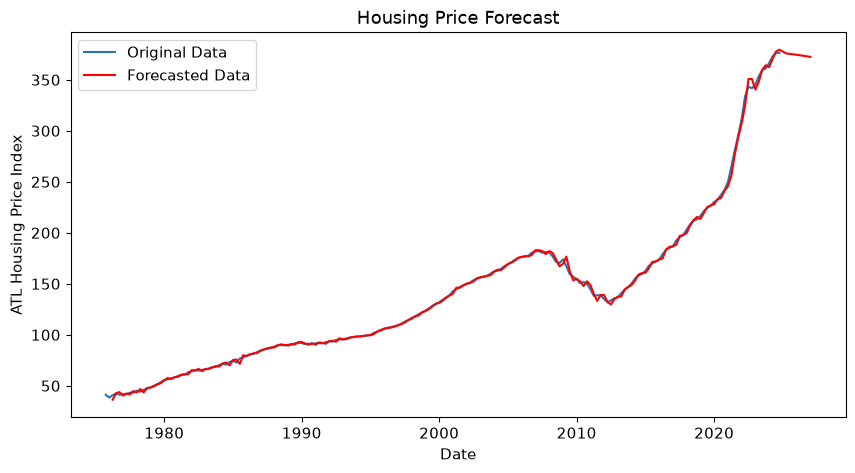

In [6]:
# Hide the warnings in the output of the notebook
import warnings
warnings.filterwarnings('ignore')

# Create a forecast with Partial Autoregression LAG 2 over the entire dataset, and then forecast the next 8 quarters (2 years) of the ATL Housing Price Index
def forecast_with_partial_autoregression(df, lag=2, forecast_periods=8):
  df = df.copy()
  df.index = pd.to_datetime(df.index)
  df = df.sort_index(ascending=True)

  model = sm.tsa.ARIMA(df['ATL_Housing_Price_Index'], order=(lag, 0, 0))
  model_fit = model.fit()

  # 1. In-sample predictions starting after the first `lag` (2) rows
  in_sample = model_fit.fittedvalues.iloc[lag:]
  in_sample_df = pd.DataFrame(
      {'Forecast': in_sample.to_numpy()}, index=df.index[lag:]
  )

  # 2. Out-of-sample forecast for the next `forecast_periods` quarters
  future_steps = model_fit.forecast(steps=forecast_periods)
  future_index = pd.date_range(
      start=df.index[-1] + pd.DateOffset(months=3),
      periods=forecast_periods,
      freq='QE',
  )
  future_df = pd.DataFrame(
      {'Forecast': future_steps.to_numpy()}, index=future_index
  )

  # Combine in chronological order
  forecast_df = pd.concat([in_sample_df, future_df], axis=0).sort_index(
      ascending=True
  )
  return forecast_df
# Create a forecast with Partial Autoregression LAG 2 over the entire dataset, and then forecast the next 8 quarters (2 years) of the ATL Housing Price Index
forecast_df = forecast_with_partial_autoregression(df, lag=2, forecast_periods=8)

# Plot the original data and the forecasted values on the same plot, which the original code does not do, and make sure to label the axes and the title of the plot
# Ensure datetime indices
df.index = pd.to_datetime(df.index)
forecast_df.index = pd.to_datetime(forecast_df.index)

plt.figure(figsize=(10, 5))
plt.plot(df.index, df['ATL_Housing_Price_Index'], label='Original Data')
plt.plot(forecast_df.index, forecast_df['Forecast'], label='Forecasted Data', color='red')
plt.xlabel('Date')
plt.ylabel('ATL Housing Price Index')
plt.title('Housing Price Forecast')
plt.legend()
plt.show()

# Hide the warnings in the output of the notebook
import warnings
warnings.filterwarnings('ignore')


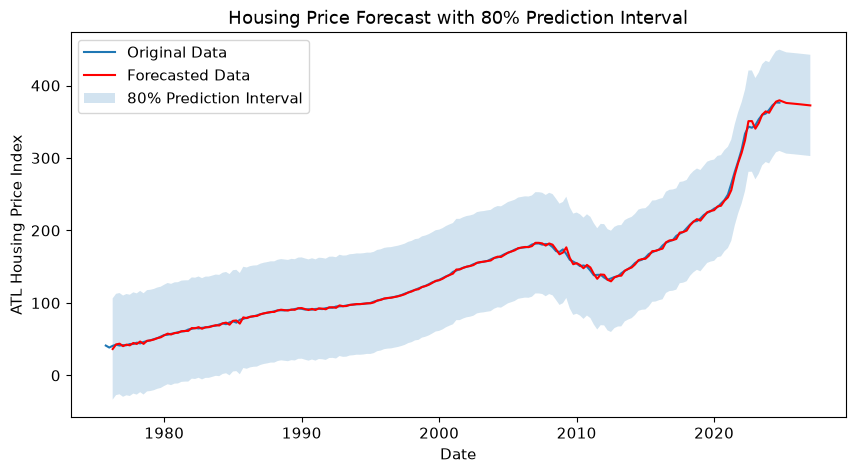

In [7]:
# Graph the forecast, original data, and the 80% prediction interval
plt.figure(figsize=(10, 5))
plt.plot(df.index, df['ATL_Housing_Price_Index'], label='Original Data')
plt.plot(forecast_df.index, forecast_df['Forecast'], label='Forecasted Data', color='red')
plt.fill_between(forecast_df.index, forecast_df['Forecast'] - 0.8 * forecast_df['Forecast'].std(), forecast_df['Forecast'] + 0.8 * forecast_df['Forecast'].std(), alpha=0.2, label='80% Prediction Interval')
plt.xlabel('Date')
plt.ylabel('ATL Housing Price Index')
plt.title('Housing Price Forecast with 80% Prediction Interval')
plt.legend()
plt.show()

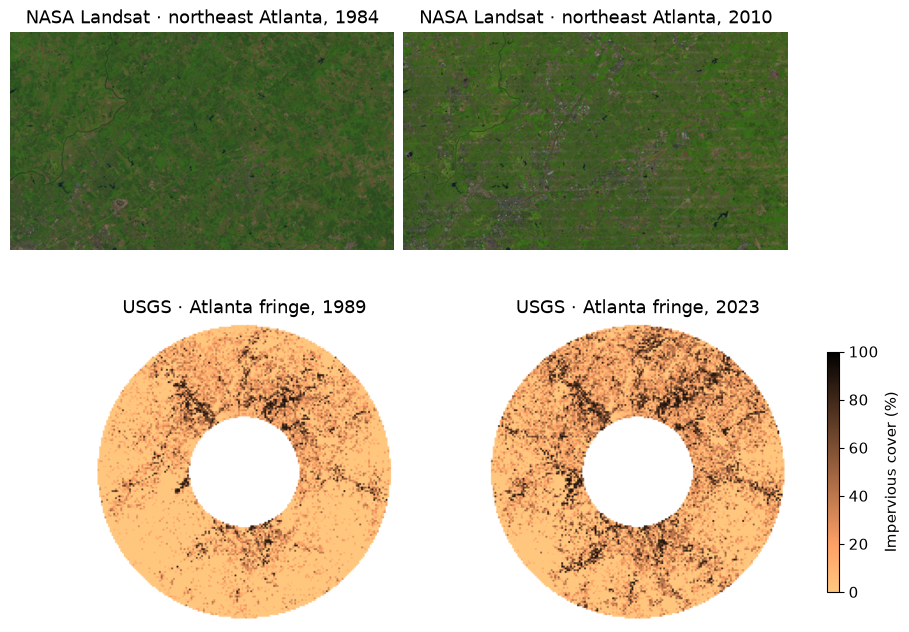

In [8]:
# Grab image data and display it for Northeast Atlanta
bundle = np.load(io.BytesIO(base64.b64decode('...')))
cities = ["Atlanta", "Charlotte", "Nashville", "Raleigh"]
maps = bundle["maps"].astype(float)
maps[maps == 255] = np.nan  # Outside the ring or missing.
prices = pd.DataFrame(bundle["q4"], index=range(1988, 2025), columns=cities)

fig, axes = plt.subplots(2, 2, figsize=(9, 6.4), constrained_layout=True)
for ax, photo, year in zip(axes[0], bundle["photos"], [1984, 2010]):
    ax.imshow(photo)
    ax.set_title(f"NASA Landsat · northeast Atlanta, {year}")
for ax, grid, year in zip(axes[1], maps[[0, -1], 0], [1989, 2023]):
    image = ax.imshow(grid, cmap="copper_r", vmin=0, vmax=100)
    ax.set_title(f"USGS · Atlanta fringe, {year}")
for ax in axes.flat:
    ax.axis("off")
fig.colorbar(image, ax=axes[1].tolist(), label="Impervious cover (%)", shrink=0.8)
plt.show()

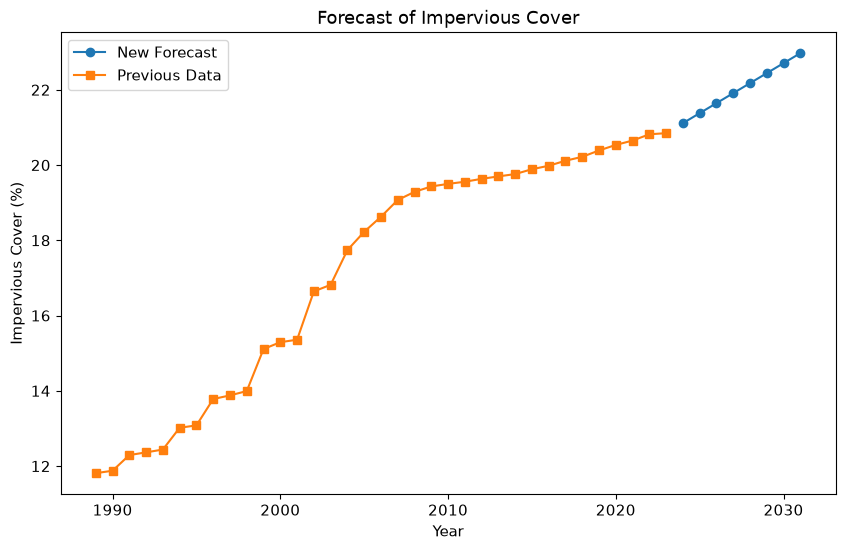

In [10]:
# Combine the sattelite images with the previous forecast to create a new forecast for the next 8 years.
# The new forecast will take into account the changes in impervious cover observed in the satellite images.
growth_rate = (maps[-1, 0] - maps[0, 0]) / (2023 - 1989)  # Calculate growth rate of impervious cover
new_forecast_years = range(2024, 2032)
new_forecast_values = [maps[0, 0] + (year - 2023) * growth_rate for year in new_forecast_years]

# Create a new DataFrame for the new forecast
# Convert each Atlanta map into one scalar: mean impervious cover.
# The map array has shape (year, city, rows, columns).
map_array = bundle["maps"].astype(float)
map_array[map_array == 255] = np.nan

years = np.arange(1989, 1989 + map_array.shape[0])
maps = pd.DataFrame(
    {
        "Impervious Cover (%)": np.nanmean(
            map_array[:, 0, :, :], axis=(1, 2)
        )
    },
    index=years,
)

growth_rate = (
    maps.loc[2023, "Impervious Cover (%)"]
    - maps.loc[1989, "Impervious Cover (%)"]
) / (2023 - 1989)

new_forecast_years = range(2024, 2032)
new_forecast_values = [
    maps.loc[2023, "Impervious Cover (%)"]
    + (year - 2023) * growth_rate
    for year in new_forecast_years
]

new_forecast = pd.DataFrame(
    new_forecast_values,
    index=new_forecast_years,
    columns=["Impervious Cover (%)"],
)

# Plot the new forecast along with the previous data
plt.figure(figsize=(10, 6))
plt.plot(new_forecast.index, new_forecast["Impervious Cover (%)"], label="New Forecast", marker="o")
plt.plot(maps.index, maps["Impervious Cover (%)"], label="Previous Data", marker="s")
plt.xlabel("Year")
plt.ylabel("Impervious Cover (%)")
plt.title("Forecast of Impervious Cover")
plt.legend()
plt.show()


# Use hybrid/sequential forecasting to use ML on the residuals
Think about other unstructured data and deep learning methods to add to the model.